# Task 2 EDA: Patronising and Condescending Language (PCL)


## 0. Setup and Imports

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

current_working_directory = Path.cwd().resolve()
candidate_roots = [current_working_directory] + list(current_working_directory.parents[:4])
PROJECT_ROOT = None
for candidate in candidate_roots:
    if (candidate / "data" / "raw" / "dontpatronizeme_pcl.tsv").exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root containing data/raw/dontpatronizeme_pcl.tsv. "
        f"Current working directory: {current_working_directory}"
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURE_DIR = PROJECT_ROOT / "EDA" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Figures will be saved to: {FIGURE_DIR}")


Project root: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3
Data directory: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3\data\raw
Figures will be saved to: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3\EDA\figures


## 1. Loading the Official Labeled Data


In [2]:
def parse_integer_identifier(raw_identifier):
    cleaned_identifier = str(raw_identifier).replace("@@", "").strip()
    if cleaned_identifier.isdigit():
        return int(cleaned_identifier)
    return None


def load_labelled_pcl_dataset(dataset_path: Path) -> pd.DataFrame:
    parsed_rows = []
    with dataset_path.open("r", encoding="utf-8", errors="replace") as file_handle:
        for text_line in file_handle:
            if text_line.startswith("---") or text_line.startswith("The Don"):
                continue

            cleaned_line = text_line.rstrip("\n")
            if not cleaned_line:
                continue

            columns = cleaned_line.split("\t")
            if len(columns) != 6:
                continue

            paragraph_id, article_id, keyword, country_code, paragraph_text, ordinal_label = columns
            parsed_paragraph_id = parse_integer_identifier(paragraph_id)
            if parsed_paragraph_id is None:
                continue

            parsed_rows.append(
                {
                    "par_id": parsed_paragraph_id,
                    "art_id": str(article_id),
                    "keyword": str(keyword),
                    "country": str(country_code),
                    "text": str(paragraph_text),
                    "label_ordinal": int(ordinal_label),
                }
            )

    labelled_dataframe = pd.DataFrame(parsed_rows)
    labelled_dataframe["label_bin"] = (labelled_dataframe["label_ordinal"] >= 2).astype(int)
    return labelled_dataframe


full_df = load_labelled_pcl_dataset(DATA_DIR / "dontpatronizeme_pcl.tsv")
train_ids = pd.read_csv(DATA_DIR / "train_semeval_parids-labels.csv")
dev_ids = pd.read_csv(DATA_DIR / "dev_semeval_parids-labels.csv")

train_df = train_ids[["par_id"]].merge(full_df, on="par_id", how="left", validate="one_to_one")
dev_df = dev_ids[["par_id"]].merge(full_df, on="par_id", how="left", validate="one_to_one")

if train_df["text"].isna().any() or dev_df["text"].isna().any():
    missing_train = int(train_df["text"].isna().sum())
    missing_dev = int(dev_df["text"].isna().sum())
    raise ValueError(f"Missing rows after merge. train={missing_train}, dev={missing_dev}")

train_df = train_df.copy()
dev_df = dev_df.copy()
train_df["split"] = "train"
dev_df["split"] = "dev"
eda_df = pd.concat([train_df, dev_df], ignore_index=True)

print(f"Train rows: {len(train_df):,}")
print(f"Dev rows:   {len(dev_df):,}")
print(f"Combined:   {len(eda_df):,}")


Train rows: 8,375
Dev rows:   2,094
Combined:   10,469


## 2. Confirming split sizes and positive class rate


In [3]:
snapshot = (
    eda_df.groupby("split")
    .agg(
        samples=("par_id", "size"),
        positive_rate=("label_bin", "mean"),
        positive_count=("label_bin", "sum"),
    )
    .reset_index()
)
snapshot["positive_rate"] = (snapshot["positive_rate"] * 100).round(2)
snapshot


,split,samples,positive_rate,positive_count
0,dev,2094,9.50,199
1,train,8375,9.48,794


## Technique 1: Basic Statistical Profiling (Class Imbalance + Token Count Distribution)

I've examined two structural properties of the dataset: (a) binary class distribution and (b) token-count distribution per class. 


In [4]:
eda_df["token_count"] = eda_df["text"].fillna("").astype(str).str.split().str.len()

class_table = (
    eda_df.groupby(["split", "label_bin"]) 
    .size()
    .rename("count")
    .reset_index()
)
class_table["label_name"] = class_table["label_bin"].map({0: "No PCL", 1: "PCL"})
class_table["pct_within_split"] = (
    class_table["count"] / class_table.groupby("split")["count"].transform("sum") * 100
).round(2)

length_summary = (
    eda_df.groupby("label_bin")["token_count"]
    .describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
    .round(2)
    .rename(index={0: "No PCL", 1: "PCL"})
)

class_table


,split,label_bin,count,label_name,pct_within_split
0,dev,0,1895,No PCL,90.50
1,dev,1,199,PCL,9.50
2,train,0,7581,No PCL,90.52
3,train,1,794,PCL,9.48


Saved figure: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3\EDA\figures\technique1_class_and_token_profile.png


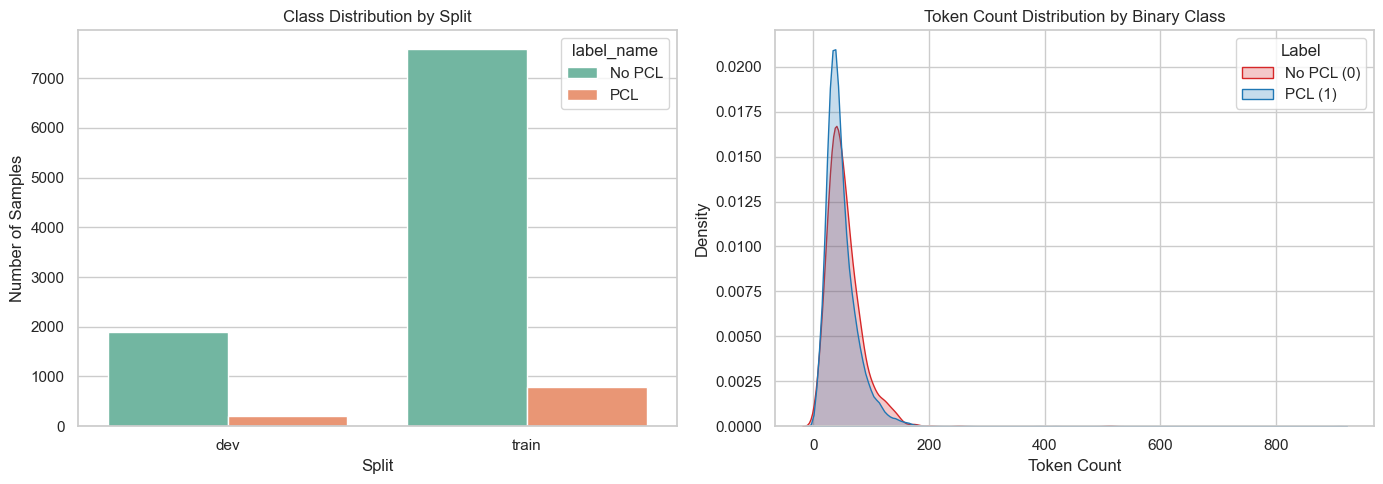

,count,mean,std,min,25%,50%,75%,max
label_bin,,,,,,,,
No PCL,9476.0,47.88,28.62,0.0,30.0,42.0,59.0,909.0
PCL,993.0,53.62,32.78,6.0,33.0,47.0,67.0,512.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution by split
plot_df = class_table.copy()
sns.barplot(
    data=plot_df,
    x="split",
    y="count",
    hue="label_name",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Class Distribution by Split")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Number of Samples")

# Token count distribution by class
sns.kdeplot(
    data=eda_df,
    x="token_count",
    hue="label_bin",
    common_norm=False,
    fill=True,
    alpha=0.25,
    palette={0: "#1f77b4", 1: "#d62728"},
    ax=axes[1],
)
axes[1].set_title("Token Count Distribution by Binary Class")
axes[1].set_xlabel("Token Count")
axes[1].set_ylabel("Density")
axes[1].legend(title="Label", labels=["No PCL (0)", "PCL (1)"])

plt.tight_layout()
tech1_figure_path = FIGURE_DIR / "technique1_class_and_token_profile.png"
fig.savefig(tech1_figure_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {tech1_figure_path}")
plt.show()

length_summary


## Technique 2: Class-Discriminative Lexical Analysis (Unigram + Bigram Log-Ratio)


In [6]:
vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_features=30000,
)

X = vectorizer.fit_transform(eda_df["text"].fillna(""))
feature_names = np.array(vectorizer.get_feature_names_out())

y = eda_df["label_bin"].to_numpy()
pos_mask = y == 1
neg_mask = y == 0

# Smoothed class-conditional frequencies
alpha = 1.0
pos_counts = np.asarray(X[pos_mask].sum(axis=0)).ravel() + alpha
neg_counts = np.asarray(X[neg_mask].sum(axis=0)).ravel() + alpha

pos_probs = pos_counts / pos_counts.sum()
neg_probs = neg_counts / neg_counts.sum()

log_ratio = np.log(pos_probs / neg_probs)

k = 15
top_pos_idx = np.argsort(log_ratio)[-k:][::-1]
top_neg_idx = np.argsort(log_ratio)[:k]

top_pos = pd.DataFrame(
    {
        "ngram": feature_names[top_pos_idx],
        "log_ratio": log_ratio[top_pos_idx],
        "pos_count": pos_counts[top_pos_idx].astype(int),
        "neg_count": neg_counts[top_pos_idx].astype(int),
    }
)

top_neg = pd.DataFrame(
    {
        "ngram": feature_names[top_neg_idx],
        "log_ratio": log_ratio[top_neg_idx],
        "pos_count": pos_counts[top_neg_idx].astype(int),
        "neg_count": neg_counts[top_neg_idx].astype(int),
    }
)

print("Top PCL-associated n-grams")
display(top_pos)
print("Top No-PCL-associated n-grams")
display(top_neg)


Top PCL-associated n-grams


,ngram,log_ratio,pos_count,neg_count
0,hope hopeless,4.313496,11,1
1,prayer,3.301895,8,2
2,dole,3.168364,7,2
3,teresa,3.168364,7,2
4,smiles,3.014213,6,2
5,compassion,3.014213,15,5
6,darkness,3.014213,9,3
7,families help,2.831891,5,2
8,think poor,2.831891,5,2
9,lifting,2.831891,5,2


Top No-PCL-associated n-grams


,ngram,log_ratio,pos_count,neg_count
0,anti immigrant,-2.478848,1,81
1,anti,-2.478848,2,162
2,illegal immigrants,-2.418417,4,305
3,released,-2.303907,1,68
4,illegal,-2.241048,7,447
5,hopelessly,-2.161937,4,236
6,election,-2.109751,2,112
7,issued,-2.091732,1,55
8,eu,-2.064081,2,107
9,technology,-2.054691,1,53


Saved figure: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3\EDA\figures\technique2_discriminative_ngrams.png


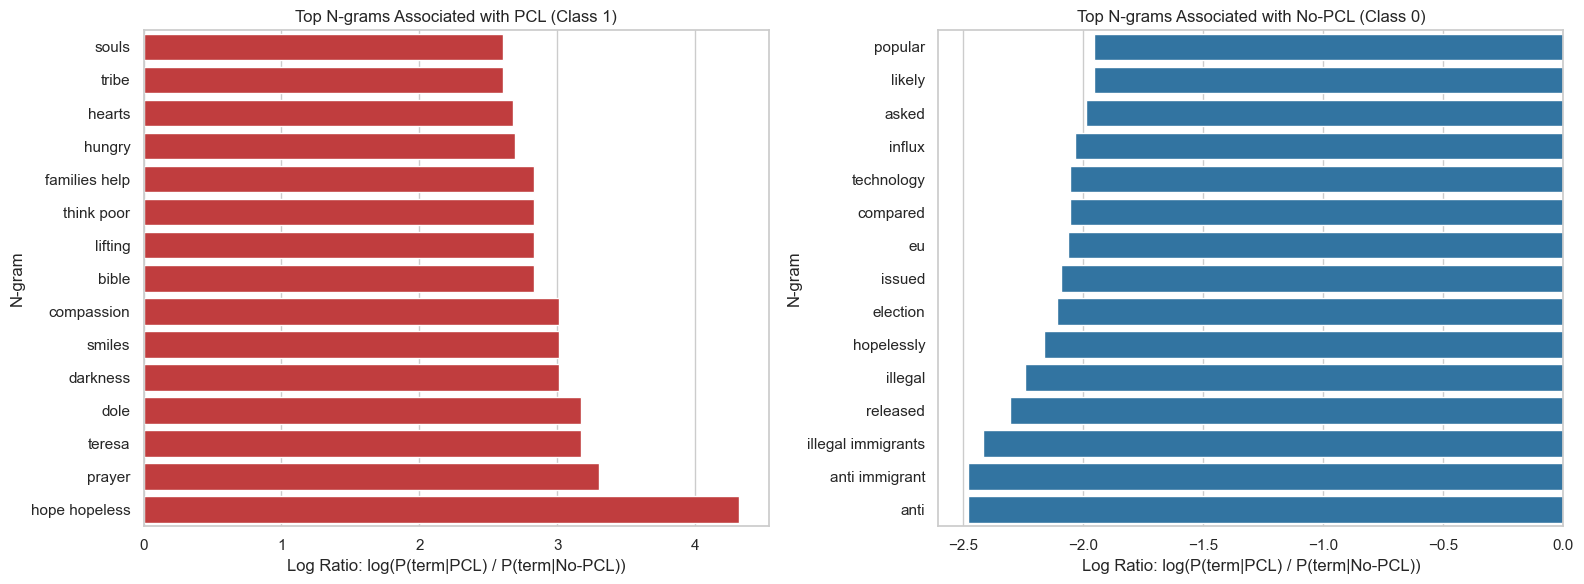

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_pos.sort_values("log_ratio", ascending=True),
    x="log_ratio",
    y="ngram",
    color="#d62728",
    ax=axes[0],
)
axes[0].set_title("Top N-grams Associated with PCL (Class 1)")
axes[0].set_xlabel("Log Ratio: log(P(term|PCL) / P(term|No-PCL))")
axes[0].set_ylabel("N-gram")

sns.barplot(
    data=top_neg.sort_values("log_ratio", ascending=False),
    x="log_ratio",
    y="ngram",
    color="#1f77b4",
    ax=axes[1],
)
axes[1].set_title("Top N-grams Associated with No-PCL (Class 0)")
axes[1].set_xlabel("Log Ratio: log(P(term|PCL) / P(term|No-PCL))")
axes[1].set_ylabel("N-gram")

plt.tight_layout()
tech2_figure_path = FIGURE_DIR / "technique2_discriminative_ngrams.png"
fig.savefig(tech2_figure_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {tech2_figure_path}")
plt.show()
